In [1]:
from hexgrid import HexCoord, HexGrid, build_obstacle_map, VelocityState, get_neighbors_at_radius, hdist
from hexstarrl import ReplayBuffer, ExperienceCollector, EnvironmentStore, HUNetTDTrainer, HUNetStateEncoder, ValueNetwork_HUNet, RLState

from hexstar import HStarProblem, HStarSearch, h_cost_travel_time_euclidean, construct_full_solution, BidHStarSearch, calculate_path_smoothness, travel_time_euclidean
from hexplot import plot_hex_grid_2

from tqdm.auto import tqdm

from dataclasses import dataclass

import random
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

from collections import defaultdict
import torch.nn as nn


In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)


Device: cuda


In [3]:
center = HexCoord(0,0)
start_v = VelocityState(0, None) # 0 speed, unspecified direction (allows expansion in any direction at root)
goal_v = VelocityState(0, None) # matches any direction as long as location matches. 

GOAL=HexCoord(q=-2, r=-2)

a_max = 3 # acceleration ability
a_min = 1 # deceleration ability
a_lat = 7 # maximum lateral g-force allowed by the agent

In [4]:
num_maps = 20
radius = 50
hex_size = 1
obs_densities = [0.05, 0.30] # Random range
n_step = 1

In [5]:
def random_start_goal(center, radius, min_distance_ratio=0.5):
    while True:
        q1 = random.randint(-radius + 1, radius - 1)
        r1 = random.randint(
            max(-radius + 1, -q1 - radius + 1),
            min(radius - 1, -q1 + radius - 1)
        )

        q2 = random.randint(-radius + 1, radius - 1)
        r2 = random.randint(
            max(-radius + 1, -q2 - radius + 1),
            min(radius - 1, -q2 + radius - 1)
        )

        start = HexCoord(center.q + q1, center.r + r1)
        goal = HexCoord(center.q + q2, center.r + r2)

        distance = (
            abs(start.q - goal.q)
            + abs(start.r - goal.r)
            + abs((start.q + start.r) - (goal.q + goal.r))
        ) // 2

        if distance >= radius * min_distance_ratio:
            return start, goal

In [6]:
replay_buffer = ReplayBuffer(
    capacity=2_000_000,
    solution_fraction=0.20,
)
environment_store = EnvironmentStore()
experience_collector = ExperienceCollector(replay_buffer, environment_store)

encoder = HUNetStateEncoder()

value_network = ValueNetwork_HUNet(
    encoder=encoder,
)

trainer = HUNetTDTrainer(
    model=value_network,
    replay_buffer=replay_buffer,
    environment_store=environment_store,
    learning_rate=1e-3,
    gamma=1.0,
    target_update_every=100,
    solution_weight=0.8,
    nonterminal_weight=0.2,
)

In [7]:
seed=0
obs_density = random.uniform(*obs_densities)
n = int(obs_density * 3 * radius * (radius + 1))

start, goal = random_start_goal(
    center,
    radius,
    min_distance_ratio=0.60,
)
obstacles = set(
    build_obstacle_map(
        center=center,
        radius=radius,
        seed=seed,
        exclude=[start, goal],
        types=[
            (
                "clustered_n",
                {
                    "n": 100,
                    "min_cluster_size": 40,
                    "max_cluster_size": 60,
                    "exclude_radius": 5,
                },
            )
        ],
    ).keys()
)
hex_grid = HexGrid(
    hex_size,
    obstacles = obstacles,
    center = center,
    radius = radius,
)
environment_store.add(
    seed, # environment_id
    hex_grid,
)
obstacles.update(
    get_neighbors_at_radius(
        HexCoord(0, 0),
        radius,
    )
)

hex_grid = HexGrid(
    hex_size,
    obstacles = obstacles,
    center = center,
    radius = radius,
)

In [8]:
problem = HStarProblem(
    hex_grid,
    start,
    goal,
    a_max,  
    a_min,  
    start_v = start_v,
    goal_v = goal_v,
    collision_radius = 0,
    heuristic = h_cost_travel_time_euclidean,
    n_step = n_step,
)

In [9]:
hs = BidHStarSearch(
    problem=problem,
    bidirectional=False,
    experience_collector=experience_collector,
    environment_id=seed,
    online_trainer=trainer,
    online_batch_size=16,
    online_training_steps=1,
)

In [10]:
for i in range(5):
    
    fsolution = hs.search()
    f_soln_path = construct_full_solution(fsolution)
    print(i, end='|')

0|1|2|3|4|

In [11]:
benchmarks = hs.get_benchmarks()

benchmarks["online_last_metrics"]


{'loss': 52.892967224121094,
 'grounded_loss': 65.04148864746094,
 'nonterminal_loss': 0.24936123192310333,
 'grounded_samples': 13,
 'nonterminal_samples': 3}

In [12]:
benchmarks.keys()

dict_keys(['nodes_reached', 'nodes_expanded', 'forward_nodes_reached', 'reverse_nodes_reached', 'forward_nodes_expanded', 'reverse_nodes_expanded', 'search_time', 'solution_cost', 'solution_length', 'solution_depth', 'effective_branching_factor', 'open_set_sizes', 'closed_set_sizes', 'forward_open_set_sizes', 'reverse_open_set_sizes', 'forward_closed_set_sizes', 'reverse_closed_set_sizes', 'iterations', 'join_checks', 'join_found', 'meeting_location', 'progress_snapshots', 'online_training_steps', 'online_training_history', 'online_last_metrics', 'backtrack_count', 'backtrack_nodes_repaired', 'backtrack_max_nodes_repaired', 'backtrack_nodes_per_trigger', 'integrated_curvature_squared', 'total_absolute_curvature', 'heading_changes', 'minimum_turning_radius'])

In [13]:
import matplotlib.pyplot as plt


def plot_online_training(benchmarks):
    """Plot online value-network training metrics."""

    history = benchmarks.get(
        "online_training_history",
        [],
    )

    if not history:
        print("No online training history.")
        return

    steps = range(
        1,
        len(history) + 1,
    )

    loss = [
        m["loss"]
        for m in history
    ]

    solution_loss = [
        m["grounded_loss"]
        for m in history
    ]

    nonterminal_loss = [
        m["nonterminal_loss"]
        for m in history
    ]

    solution_samples = [
        m["grounded_samples"]
        for m in history
    ]

    nonterminal_samples = [
        m["nonterminal_samples"]
        for m in history
    ]

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 4),
    )

    # ---------------------------------------------------------
    # Loss
    # ---------------------------------------------------------

    axes[0].plot(
        steps,
        loss,
        label="Overall Loss",
    )

    axes[0].plot(
        steps,
        solution_loss,
        label="Solution Loss",
    )

    axes[0].plot(
        steps,
        nonterminal_loss,
        label="Nonterminal Loss",
    )

    axes[0].set_xlabel(
        "Training Step"
    )

    axes[0].set_ylabel(
        "MSE Loss"
    )

    axes[0].set_title(
        "Online Training Loss"
    )

    axes[0].legend()

    # ---------------------------------------------------------
    # Samples contributing to training
    # ---------------------------------------------------------

    axes[1].plot(
        steps,
        solution_samples,
        label="Solution Samples",
    )

    axes[1].plot(
        steps,
        nonterminal_samples,
        label="Nonterminal Samples",
    )

    axes[1].set_xlabel(
        "Training Step"
    )

    axes[1].set_ylabel(
        "Samples"
    )

    axes[1].set_title(
        "Training Sample Composition"
    )

    axes[1].legend()

    plt.tight_layout()
    plt.show()

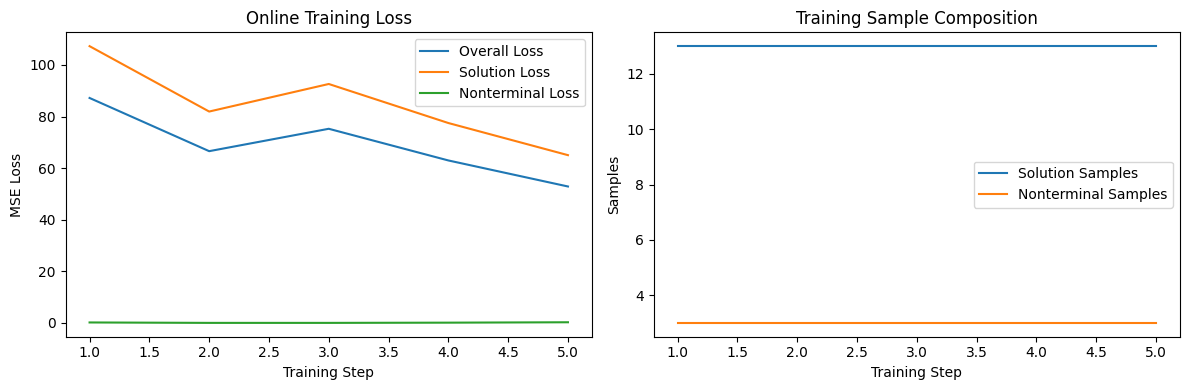

In [14]:
benchmarks = hs.get_benchmarks()

plot_online_training(
    benchmarks
)

In [15]:
nope = {
    'open_set_sizes',
    'closed_set_sizes',
    'forward_open_set_sizes',
    'forward_closed_set_sizes',
}

In [16]:
{print(k,v) for k,v in benchmarks.items() if k not in nope}

nodes_reached 37076
nodes_expanded 4119
forward_nodes_reached 37076
reverse_nodes_reached 0
forward_nodes_expanded 4119
reverse_nodes_expanded 0
search_time 1.0844461917877197
solution_cost 17.0604379559792
solution_length 24
solution_depth None
effective_branching_factor None
reverse_open_set_sizes []
reverse_closed_set_sizes []
iterations 0
join_checks 0
join_found False
meeting_location None
progress_snapshots []
online_training_steps 5
online_training_history [{'loss': 87.21039581298828, 'grounded_loss': 107.29544830322266, 'nonterminal_loss': 0.1751411408185959, 'grounded_samples': 13, 'nonterminal_samples': 3}, {'loss': 66.58497619628906, 'grounded_loss': 81.94865417480469, 'nonterminal_loss': 0.009064584039151669, 'grounded_samples': 13, 'nonterminal_samples': 3}, {'loss': 75.2661361694336, 'grounded_loss': 92.63298797607422, 'nonterminal_loss': 0.009802109561860561, 'grounded_samples': 13, 'nonterminal_samples': 3}, {'loss': 62.98509216308594, 'grounded_loss': 77.49767303466797

{None}